# News_Category_Dataset
The raw data is uploaded here.

In [91]:
import pandas as pd
df=pd.read_json("News_Category_Dataset_v3.json",lines=True)

print(df.info())
print("_"*67)
print(df["category"].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209527 entries, 0 to 209526
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   link               209527 non-null  object        
 1   headline           209527 non-null  object        
 2   category           209527 non-null  object        
 3   short_description  209527 non-null  object        
 4   authors            209527 non-null  object        
 5   date               209527 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 9.6+ MB
None
___________________________________________________________________
category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES 

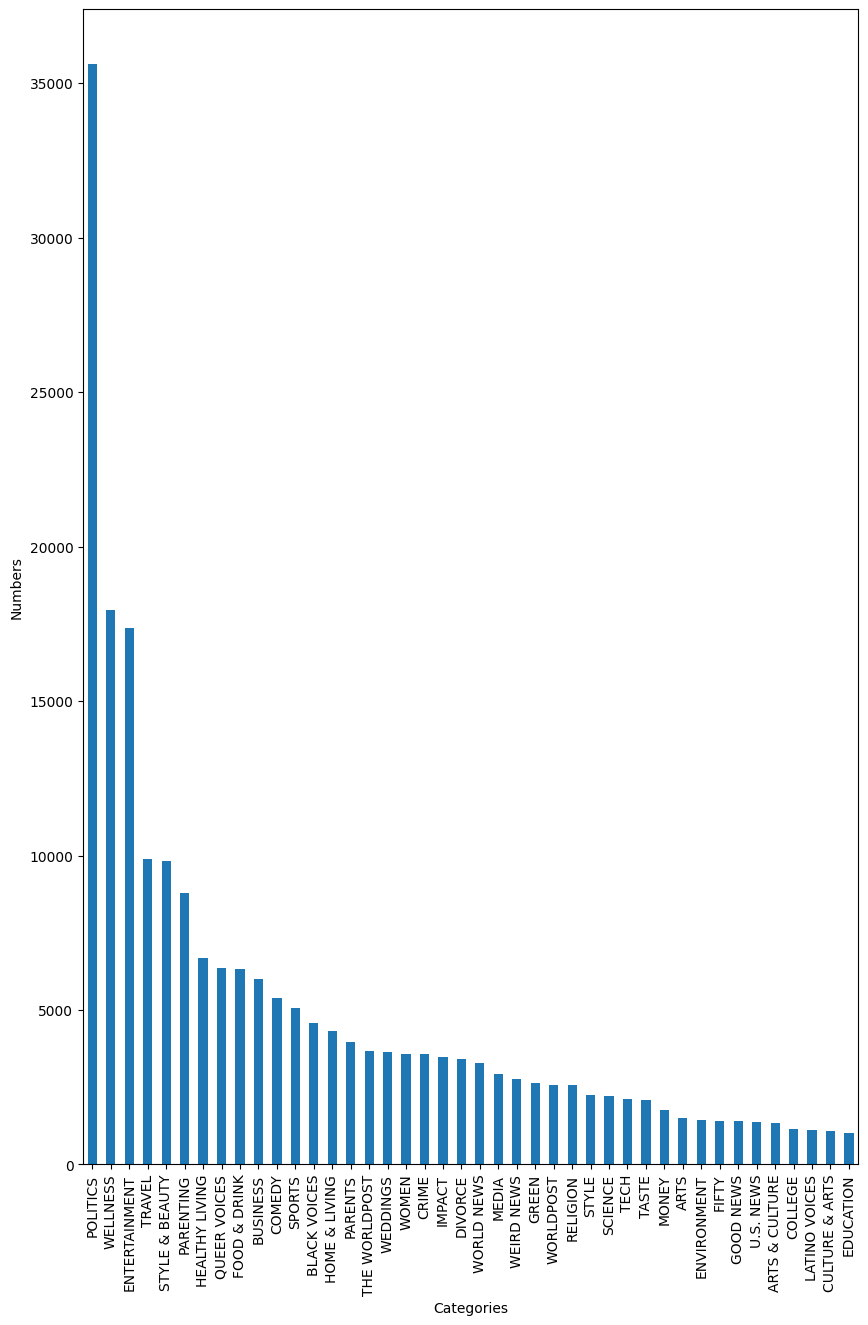

In [47]:
import matplotlib.pyplot as plot
fig=plot.figure(figsize=(10,15))
df["category"].value_counts().plot(kind="bar")
plot.xlabel("Categories")
plot.ylabel("Numbers")
plot.show()


Duplicated datas


In [48]:
print(df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values("headline")


13


,link,headline,category,short_description,authors,date
145141,https://www.huffingtonpost.comhttp://www.weather.com/news/science/environment/10-cities-could-run-out-water-20131212?pageno=1,10 Cities That Could Run Out Of Water - Weather.com,ENVIRONMENT,"Securing access to plentiful, renewable sources of fresh water is among the biggest struggles large cities around the world",,2013-12-15
145142,https://www.huffingtonpost.comhttp://www.weather.com/news/science/environment/10-cities-could-run-out-water-20131212?pageno=1,10 Cities That Could Run Out Of Water - Weather.com,ENVIRONMENT,"Securing access to plentiful, renewable sources of fresh water is among the biggest struggles large cities around the world",,2013-12-15
194596,https://www.huffingtonpost.comhttp://blogs.wsj.com/cio/2012/07/06/apple-removes-green-electronics-certification-from-products/,Apple Removes Green EPEAT Electronics Certification From Products,TECH,Apple has pulled its products off the U.S. government-backed registration of environmentally friendly electronics. Read more,,2012-07-07
194595,https://www.huffingtonpost.comhttp://blogs.wsj.com/cio/2012/07/06/apple-removes-green-electronics-certification-from-products/,Apple Removes Green EPEAT Electronics Certification From Products,TECH,Apple has pulled its products off the U.S. government-backed registration of environmentally friendly electronics. Read more,,2012-07-07
207208,https://www.huffingtonpost.comhttp://d.repubblica.it/english/fashion/2012/02/22/video/prada_video-865968/1/,Behind-The-Scenes Look At Prada's Workshop (VIDEO),STYLE & BEAUTY,"Exclusive worldwide and for the first time in her history, Prada opens the doors to the most secret areas of her laboratories",,2012-02-22
207207,https://www.huffingtonpost.comhttp://d.repubblica.it/english/fashion/2012/02/22/video/prada_video-865968/1/,Behind-The-Scenes Look At Prada's Workshop (VIDEO),STYLE & BEAUTY,"Exclusive worldwide and for the first time in her history, Prada opens the doors to the most secret areas of her laboratories",,2012-02-22
187329,https://www.huffingtonpost.comhttp://www.nytimes.com/2012/09/23/opinion/sunday/the-optimal-diet.html?hp,"Eating For Health, Not Weight",WELLNESS,"Almost half of Americans are on a diet -- not surprising, since two-thirds are overweight or obese, a frightening statistic",,2012-09-23
187328,https://www.huffingtonpost.comhttp://www.nytimes.com/2012/09/23/opinion/sunday/the-optimal-diet.html?hp,"Eating For Health, Not Weight",WELLNESS,"Almost half of Americans are on a diet -- not surprising, since two-thirds are overweight or obese, a frightening statistic",,2012-09-23
67901,https://www.huffingtonpost.comhttp://gizmodo.com/former-facebook-workers-we-routinely-suppressed-conser-1775461006,Former Facebook Workers: We Routinely Suppressed Conservative News,TECH,Facebook workers routinely suppressed news stories of interest to conservative readers from the social network’s influential,,2016-05-09
67923,https://www.huffingtonpost.comhttp://gizmodo.com/former-facebook-workers-we-routinely-suppressed-conser-1775461006,Former Facebook Workers: We Routinely Suppressed Conservative News,TECH,Facebook workers routinely suppressed news stories of interest to conservative readers from the social network’s influential,,2016-05-09


Dropped the duplicated datas

In [49]:
df=df.drop_duplicates()
df.duplicated().sum()
df[df.duplicated(keep=False)].sort_values("headline")

,link,headline,category,short_description,authors,date


Length of the headlines


In [50]:
head_len=df["headline"].str.len()
head_len.describe()
print(head_len)

0         76
1         89
2         69
3         56
4         77
          ..
209522    58
209523    69
209524    99
209525    53
209526    56
Name: headline, Length: 209514, dtype: int64


Creating the outlier

In [51]:
Q1 = head_len.quantile(0.25)
Q3 = head_len.quantile(0.75)
IQR=Q3-Q1
lower_boundary= Q1-(1.5*IQR)
Higher_boundary= Q3+(1.5*IQR)
print("lower boundary,Q1:", lower_boundary)
print("Higher boundary,Q3:", Higher_boundary)


lower boundary,Q1: 8.5
Higher boundary,Q3: 108.5


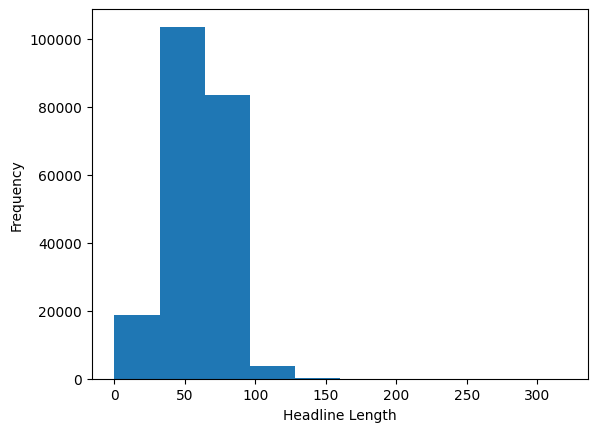

In [52]:
import numpy as np
leng=np.array(head_len)
plot.hist(leng)
plot.xlabel("Headline Length")
plot.ylabel("Frequency")
plot.show()

In [53]:
print((head_len<lower_boundary).sum())
print((head_len>Higher_boundary).sum())

218
902


Checking the Outliers

In [54]:
outliers=df[(head_len<lower_boundary)|(head_len>Higher_boundary)]["headline"]
outliers

,headline
4238,"Postmaster General Louis DeJoy Evades Responsibility For Major Post Office Delays, Refuses to Reverse Changes"
5506,Iran's Supreme Leader Ayatollah Ali Khamenei: 'Harsh Retaliation Is Waiting' For U.S. After General's Assassination
8106,Devin Nunes Is Infamous For Sabotaging The Trump-Russia Investigation. His Opponent Andrew Janz Is Running On Water.
8871,A Mostly Non-Christian Militia Won 2 Of Iraqi Christians' Parliamentary Seats. Now Christians Want Trump To Intervene.
9451,'A LITTLE EXTORTION-Y'...This Guy Figured Out What Stormy Daniels' Old Lawyer ACTUALLY DOES — And It's Not Pretty!
...,...
209131,CFDA's 'The Fashion Fund' On Hulu: Diane Von Furstenberg And Joseph Altuzarra Talk About Fashion's Most Coveted Prize (VIDEO)
209219,The Couple That Argues Together Stays Together: How Bickering Could Be The Key To A Long And Healthy Marriage
209296,"Jessica Hoppe, Blogger Behind 'Having It All' Has Become That Girl Who Shows Baby Pictures At Parties (PHOTOS)"
209483,"Jon Stewart, Dead Kennedys Fan? '80s Photo Apparently Shows Young 'Daily Show' Host At Punk Show (UPDATE: OK, Probably Not)"


In [55]:
outliers.sample(30)

,headline
153061,"Marianne Williamson Talks Transcendental Meditation, Enlightenment And Shoulder Pads In ORIGIN Magazine (PHOTOS)"
112295,Autism Without Fear: We Raise Money for Autism Research... But Not for Our Kids' Schools and Service Agencies?
161133,"Janelle Monae Releases 'Dance Apocalyptic,' Discusses New Album And How To 'Maximize Your Full Experience' With Her Music"
22138,Rewriting History The Trump Way: Trump Undermines The Rule Of Law By Supporting Sheriff Arpaio's Bid To Expunge His Criminal Record
191442,"Rachel Ashwell's Shabby Chic Design Inspiration: London Olympic Games, Downton Abbey And Her British Heritage (PHOTOS)"
99118,"Amazon's Same-Day Delivery Service Taking Hits From Unreliable Third Party Couriers and Other, Faster Options"
161269,"Celebrities With Green Homes: Jessica Alba, Lisa Ling and Four Other A-Listers With Eco-Friendly Houses (PHOTOS)"
206871,"Seth Rogen Independent Spirit Awards Monologue: Host Blasts Brett Ratner, Chris Brown And Mel Gibson In Hilarious Opening"
129360,"Kerry: It Would Have Been 'Offensive' To Leave Bergdahl With People Who Would 'Torture Him, Cut Off His Head'"
185528,I Lost Weight: Tom Dioguardi Made Over His Eating Habits With The Help Of A Dietitian Friend And Lost 100 Pounds


In [56]:
print(df.loc[109100])
print("*"*20)
print(df.loc[19578])
print(df.loc[197505]["short_description"])

link                 https://www.huffingtonpost.com/entry/disney-ceo-iger-readies-m_b_6520290.html
headline                                                                                          
category                                                                                  BUSINESS
short_description                                                                                 
authors                                        Gary Snyder, ContributorWriter and Media Strategist
date                                                                           2015-01-25 00:00:00
Name: 109100, dtype: object
********************
link                 https://www.huffingtonpost.com/entry/what-if-afghanistan-iraq-september-11_us_5a1b6de7e4b064948075419c
headline                                                                                                           What If?
category                                                                                                     

Examining the Outliers Headlines



*   Row 11503, 126860 they contains only one words which is not really usefull
*   Long headlines actually usefull



In [57]:
pd.set_option('display.max_colwidth', None)
outliers.sample(n=min(25,len(outliers)),random_state=42)


,headline
93006,HuffPost What's Working Honor Roll: Anonymous Messaging App Provides Suicide Intervention On College Campuses
37682,Trinity Lutheran v. Comer: 7 Things To Know About A SCOTUS Preschool Case With Big School Choice Implications
190218,"EXCLUSIVE: David’s Bridal Agrees To Be Acquired By Private-equity Firm Clayton, Dubilier & Rice For $900M - NYPOST.com"
199317,"Nicole Scherzinger Works High Slit At 'Men In Black 3' Premiere, Nearly Suffers Wardrobe Malfunction (PHOTOS)"
131582,'I Decide:' A Campaign Calling on World Leaders to Put Sexual and Reproductive Health and Rights at the Heart of Global Development
188295,Small Space Living: Ron Barth From Resource Furniture Shares The Benefits Of Adjusting Your Home To Your Needs
156714,"Walking the Middle Path: If You Are Out of Balance in One Area of Your Life, You Are Out of Balance in Every Area"
96875,"Kavala, Thasos, and the Joys of Off-Season Travel: Natterings From Northern Greece on the Looney Front, Part 2"
47174,"No, Donald Trump Wishing Happy New Year To His 'Many Enemies' Is In No Way the Same As Hillary Clinton's 'Basket Of Deplorables'"
100597,Young and Entrepreneurial: Brian Clark's Transformation From General Electric IT Guy to Serial Hackathon Winner and Entrepreneur


In [58]:
# Count words in each headline
df["word_count"] = df["headline"].str.split().str.len()

# Examine the distribution
print(df["word_count"].describe())

# Count headlines by word count
print(df["word_count"].value_counts().sort_index().head(15))

count    209514.000000
mean          9.600762
std           3.068503
min           0.000000
25%           8.000000
50%          10.000000
75%          12.000000
max          44.000000
Name: word_count, dtype: float64
word_count
0         6
1       256
2      1428
3      3333
4      6072
5      9234
6     13273
7     17418
8     22261
9     26335
10    28151
11    26390
12    21098
13    14743
14     9012
Name: count, dtype: int64


In [59]:
# Counted headlines containing fewer than 1 words
short_headlines = df[
    df["headline"].str.split().str.len() < 1
]

print("Number of short headlines:", len(short_headlines))

short_headlines["headline"].sample(
    n=min(20, len(short_headlines)),
    random_state=42
)

Number of short headlines: 6


,headline
90944,
95567,
122145,
103675,
110153,
109100,


In [60]:
print(df.loc[90944])
print(df.loc[95567])
print(df.loc[122145])
print(df.loc[103675])

link                                             https://www.huffingtonpost.com/entry/lincoln-20_b_8023742.html
headline                                                                                                       
category                                                                                               POLITICS
short_description                                                                                              
authors              Robert Moran, ContributorRobert Moran leads Brunswick Insight, and writes and speaks on...
date                                                                                        2015-08-22 00:00:00
word_count                                                                                                    0
Name: 90944, dtype: object
link                                                                                                                                 https://www.huffingtonpost.com/entry/post_9671_b_7683632

In [61]:
#deleting the empty headlines

df = df[
    df["headline"].notna()
    & df["headline"].str.strip().ne("")
].copy()

In [62]:
# Count words in each headline
df["word_count"] = df["headline"].str.split().str.len()

# Examine the distribution
print(df["word_count"].describe())

# Count headlines by word count
print(df["word_count"].value_counts().sort_index().head(15))

count    209508.000000
mean          9.601037
std           3.068116
min           1.000000
25%           8.000000
50%          10.000000
75%          12.000000
max          44.000000
Name: word_count, dtype: float64
word_count
1       256
2      1428
3      3333
4      6072
5      9234
6     13273
7     17418
8     22261
9     26335
10    28151
11    26390
12    21098
13    14743
14     9012
15     5175
Name: count, dtype: int64


In [63]:
# Count headlines containing fewer than 2 words
short_headlines = df[
    df["headline"].str.split().str.len() < 2
]

print("Number of short headlines:", len(short_headlines))

short_headlines[
    ["headline", "short_description"]
].sample(
    n=min(20, len(short_headlines)),
    random_state=42
)

Number of short headlines: 256


,headline,short_description
190205,Recipes,"Both of you seem to be confused concerning what a ""meal"" is. Meals aren't supposed to be punishment, they are supposed to be delicious."
37983,Anti-Lent,"Even though I was not raised Catholic, I always enjoyed the idea of giving something up for Lent. I remember viewing it as"
119444,Praying,"It's the Jewish new year. Big holiday. Obscene amounts of food. Long hours in the synagogue. This year, I did something different. Instead of using the synagogue prayer book designated for the holiday, I took my own prayer book."
177307,Legacies,"Last week, as I thought about 2013 resolutions and reflected on the events of 2012, I realized that I am often so consumed with work and bills (the ""reason"" I have to work) that I neglect the ""real"" reasons that I have to work -- my family and myself."
130417,Frozen,"Learning to love technology, to embrace it and use it well, may involve early crashing into each other, but in the long run, it can be a great tool of connection."
166905,Inspiration,"""I turn 100 on August 5! That's something to be excited about! Thank you for your help with the hill, young man."" As he started to walk away, I had to smile myself, because initially I had thought that I was the one doing the good deed of the day."
201297,Kissing,"Our human makeup fundamentally consists of vibration, making the brain resonate with other vibrations it encounters such"
158292,Grief,"Trying to make sense of a father and son dying, trying to fit that into my understanding of how the universe is operating... my understanding of the Dharma... my understanding of my dharma... A complete mystery. And for me also a tragedy. So today I went to yoga class drunk."
47536,#BlackMenLove,I once asked men to #TwitpicYourFlowerCrown on Twitter. It started out as me poking fun at the all too popular flower crown
94996,Love?,"One may label it 'loving' all day long, profess it from the rooftops and paint it across the sky, but love it is not. Love does not exist in a dark cave of longing and desperation. Those feelings are the offspring of fear."


In [64]:
print

<function print(*args, sep=' ', end='\n', file=None, flush=False)>

Checking duplicated files again

In [65]:
#Exact duplicate rows
print("Full-row duplicates:", df.duplicated().sum())

Full-row duplicates: 0


In [66]:
#Duplicate headlines
print("Duplicate headlines:",
      df.duplicated(subset=["headline"]).sum())
# print(
#     duplicate_headlines[
#         ["headline", "category", "short_description"]
#     ].head(20).to_string(index=False)
# )

Duplicate headlines: 1513


In [67]:
print("Repeated headline rows:",
      df.duplicated(subset=["headline"]).sum())

print("Unique headline values:",
      df["headline"].nunique())

Repeated headline rows: 1513
Unique headline values: 207995


In [68]:
# Find headlines associated with multiple categories
category_counts = (
    df.groupby("headline")["category"]
      .nunique()
)

conflicting_headlines = category_counts[
    category_counts > 1
]

print("Headlines with conflicting categories:",
      len(conflicting_headlines))

Headlines with conflicting categories: 102


In [69]:
df[
    df["headline"].isin(conflicting_headlines.index)
][["headline", "category", "short_description"]].head(20)

,headline,category,short_description
7645,Here Are The Movies Coming To Netflix This Week,HOME & LIVING,The best Netflix movie of 2018 debuts this week.
8457,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,Netflix debuts its disaster movie of the month.
8969,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,"You have a few options this week, including a new Gillian Jacobs movie."
9303,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,Surprise! Netflix adds a pretty good sci-fi movie.
9685,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,This low-budget horror flick could be for you.
10078,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,Is this finally the week that Netflix debuts a good sci-fi thriller?
18333,Gingerbread Dessert Recipes For The Best Holiday Baking,TASTE,It's beginning to feel a lot like Christmas.
32378,Why We March,BLACK VOICES,"Tomorrow morning, a diverse coalition of North Texans will gather in downtown Dallas at the historic St. Paul United Methodist"
33649,How Successful People Stay Calm,BUSINESS,The ability to manage your emotions and remain calm under pressure has a direct link to your performance.
34663,Hassan Rouhani's Economic Legacy May Be His Key To Winning A Second Term,WORLD NEWS,"Shahram Akbarzadeh, Deakin University Today’s presidential election in Iran had turned into a vote of confidence for President"


Many news with same headlines are in different categories. SO I have deleted the duplicated headlines with same categories


In [70]:
df.drop_duplicates(
    subset=["headline", "category"],
    keep="first",
    inplace=True
)

In [71]:
print(
    "Remaining duplicate headline-category pairs:",
    df.duplicated(
        subset=["headline", "category"]
    ).sum()
)

Remaining duplicate headline-category pairs: 0


In [72]:
category_count = (
    df.groupby("headline")["category"].nunique()
)

conflicting_headlines = category_count[
    category_count > 1
]

print("Conflicting headlines:", len(conflicting_headlines))
print("Current dataset shape:", df.shape)

Conflicting headlines: 102
Current dataset shape: (208102, 7)


In [73]:
df[
    df["headline"].isin(conflicting_headlines.index)
][["headline", "category", "short_description"]].head(20)

,headline,category,short_description
7645,Here Are The Movies Coming To Netflix This Week,HOME & LIVING,The best Netflix movie of 2018 debuts this week.
8457,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,Netflix debuts its disaster movie of the month.
18333,Gingerbread Dessert Recipes For The Best Holiday Baking,TASTE,It's beginning to feel a lot like Christmas.
32378,Why We March,BLACK VOICES,"Tomorrow morning, a diverse coalition of North Texans will gather in downtown Dallas at the historic St. Paul United Methodist"
33649,How Successful People Stay Calm,BUSINESS,The ability to manage your emotions and remain calm under pressure has a direct link to your performance.
34663,Hassan Rouhani's Economic Legacy May Be His Key To Winning A Second Term,WORLD NEWS,"Shahram Akbarzadeh, Deakin University Today’s presidential election in Iran had turned into a vote of confidence for President"
34881,Hassan Rouhani's Economic Legacy May Be His Key To Winning A Second Term,THE WORLDPOST,"Mohammad Ali Marizad/Tasnim News Agency/Wikipedia, CC BY-NC Shahram Akbarzadeh, Deakin University Today’s presidential"
47078,Coming Home,WOMEN,
47755,The Real History Of Hanukkah Is More Complicated Than You Thought,POLITICS,"What do you really know about the ""festival of lights""?"
50108,Dear President Obama,QUEER VOICES,"Dear President Obama, This week I watched you place the Presidential Medal of Freedom on Ellen DeGeneres as she struggled"


In [74]:
#Missing values
print(df.isnull().sum())

link                 0
headline             0
category             0
short_description    0
authors              0
date                 0
word_count           0
dtype: int64






*  There is no duplicated Headline-Category pairs
*  Conflicting headline-Category pairs: 102
* There is no more missing values in any columns

Bar Plot after data cleanisng


*   Politics have the higher frequency of datas
*   Education has the lower frequency of datas






category
POLITICS          35478
WELLNESS          17896
ENTERTAINMENT     17321
TRAVEL             9875
STYLE & BEAUTY     9330
PARENTING          8740
HEALTHY LIVING     6684
QUEER VOICES       6337
FOOD & DRINK       6335
BUSINESS           5979
COMEDY             5343
SPORTS             5076
BLACK VOICES       4574
HOME & LIVING      4214
PARENTS            3890
THE WORLDPOST      3662
WEDDINGS           3594
CRIME              3557
IMPACT             3480
WOMEN              3457
DIVORCE            3420
WORLD NEWS         3294
MEDIA              2941
WEIRD NEWS         2777
GREEN              2617
WORLDPOST          2578
RELIGION           2568
STYLE              2246
SCIENCE            2204
TASTE              2095
TECH               2049
MONEY              1754
ARTS               1509
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
ENVIRONMENT        1372
ARTS & CULTURE     1338
COLLEGE            1144
LATINO VOICES      1130
CULTURE & ARTS     1054
EDUCATI

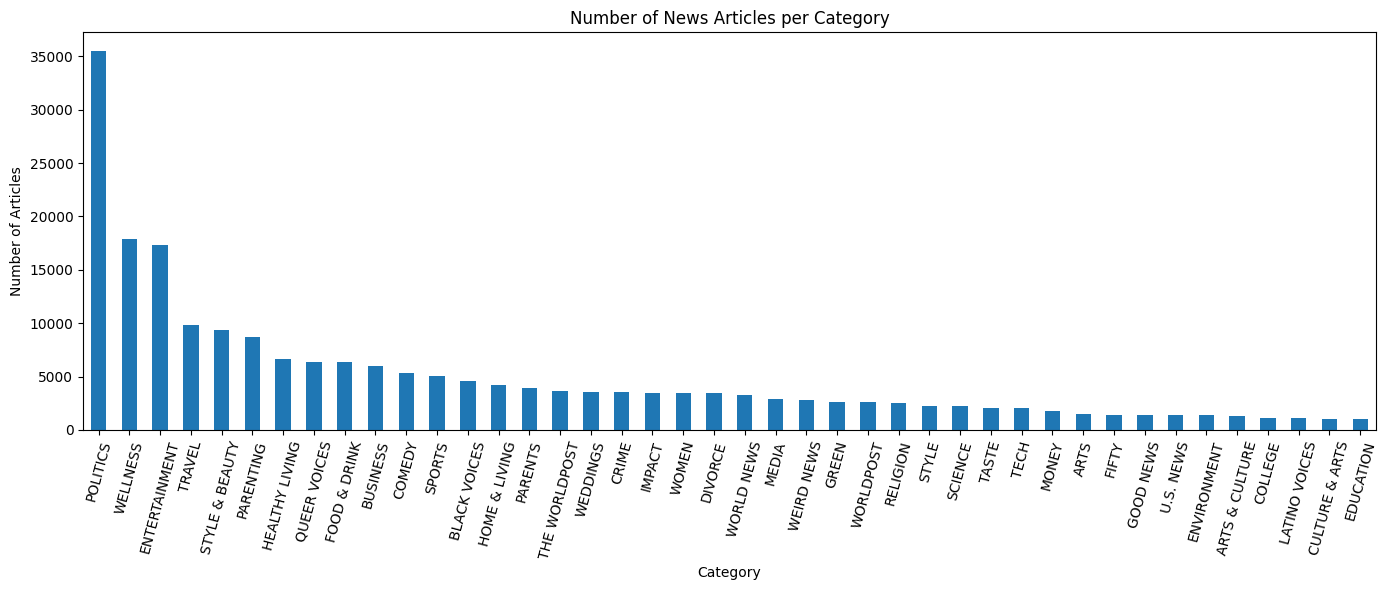

In [75]:
import matplotlib.pyplot as plt

category_counts = df["category"].value_counts()

print(category_counts)

category_counts.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Number of News Articles per Category")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [76]:
#Lowercasing all the Headlines and Descriptions
df["lower_headlines"]=df["headline"].str.lower()
df["lower_description"]=df['short_description'].str.lower()
df["category"] = df["category"].str.upper()

In [77]:
df[[
    "headline",
    "lower_headlines",
    "short_description",
    "category",
    "lower_description"
]].head(10)

,headline,lower_headlines,short_description,category,lower_description
0,Over 4 Million Americans Roll Up Sleeves For Omicron-Targeted COVID Boosters,over 4 million americans roll up sleeves for omicron-targeted covid boosters,Health experts said it is too early to predict whether demand would match up with the 171 million doses of the new boosters the U.S. ordered for the fall.,U.S. NEWS,health experts said it is too early to predict whether demand would match up with the 171 million doses of the new boosters the u.s. ordered for the fall.
1,"American Airlines Flyer Charged, Banned For Life After Punching Flight Attendant On Video","american airlines flyer charged, banned for life after punching flight attendant on video","He was subdued by passengers and crew when he fled to the back of the aircraft after the confrontation, according to the U.S. attorney's office in Los Angeles.",U.S. NEWS,"he was subdued by passengers and crew when he fled to the back of the aircraft after the confrontation, according to the u.s. attorney's office in los angeles."
2,23 Of The Funniest Tweets About Cats And Dogs This Week (Sept. 17-23),23 of the funniest tweets about cats and dogs this week (sept. 17-23),"""Until you have a dog you don't understand what could be eaten.""",COMEDY,"""until you have a dog you don't understand what could be eaten."""
3,The Funniest Tweets From Parents This Week (Sept. 17-23),the funniest tweets from parents this week (sept. 17-23),"""Accidentally put grown-up toothpaste on my toddler’s toothbrush and he screamed like I was cleaning his teeth with a Carolina Reaper dipped in Tabasco sauce.""",PARENTING,"""accidentally put grown-up toothpaste on my toddler’s toothbrush and he screamed like i was cleaning his teeth with a carolina reaper dipped in tabasco sauce."""
4,Woman Who Called Cops On Black Bird-Watcher Loses Lawsuit Against Ex-Employer,woman who called cops on black bird-watcher loses lawsuit against ex-employer,Amy Cooper accused investment firm Franklin Templeton of unfairly firing her and branding her a racist after video of the Central Park encounter went viral.,U.S. NEWS,amy cooper accused investment firm franklin templeton of unfairly firing her and branding her a racist after video of the central park encounter went viral.
5,Cleaner Was Dead In Belk Bathroom For 4 Days Before Body Found: Police,cleaner was dead in belk bathroom for 4 days before body found: police,"The 63-year-old woman was seen working at the South Carolina store on Thursday. She was found dead Monday after her family reported her missing, authorities said.",U.S. NEWS,"the 63-year-old woman was seen working at the south carolina store on thursday. she was found dead monday after her family reported her missing, authorities said."
6,Reporter Gets Adorable Surprise From Her Boyfriend While Live On TV,reporter gets adorable surprise from her boyfriend while live on tv,"""Who's that behind you?"" an anchor for New York’s PIX11 asked journalist Michelle Ross as she finished up an interview.",U.S. NEWS,"""who's that behind you?"" an anchor for new york’s pix11 asked journalist michelle ross as she finished up an interview."
7,Puerto Ricans Desperate For Water After Hurricane Fiona’s Rampage,puerto ricans desperate for water after hurricane fiona’s rampage,More than half a million people remained without water service three days after the storm lashed the U.S. territory.,WORLD NEWS,more than half a million people remained without water service three days after the storm lashed the u.s. territory.
8,How A New Documentary Captures The Complexity Of Being A Child Of Immigrants,how a new documentary captures the complexity of being a child of immigrants,"In ""Mija,"" director Isabel Castro combined music documentaries with the style of ""Euphoria"" and ""Clueless"" to tell a more nuanced immigration story.",CULTURE & ARTS,"in ""mija,"" director isabel castro combined music documentaries with the style of ""euphoria"" and ""clueless"" to tell a

In [78]:
# Check which headlines contain URLs
url_mask = df["lower_description"].str.contains(
    r"https?://|www\.",
    regex=True,
    na=False
)

# Count matching headlines
print(url_mask.sum())

# Display some matching headlines
print(df.loc[url_mask, "short_description"].head(10))

171
9763                                                                                                                           Awww.
18682                                                                                                                          Ewww.
22114                                                                                                                          Awww.
23086                                                                                                                        Awwwww.
25330    1. Call your representatives. You can find who you’re representatives are at https://whoismyrepresentative.com/ If you want
31791       5. Pack Less. My favorite travel writer, Rick Steves, https://www.ricksteves.com says there are travelers who pack light
36260                                                                                                                          Ewww.
43536                                                            

In [79]:
import re

def remove_urls(text):
    return re.sub(r"https?://\S+|www\.\S+", "", text)

df["headline_clean"] = df["lower_headlines"].apply(remove_urls)

df["description_clean"] = df["lower_description"].apply(remove_urls)

In [80]:
print(df.loc[94420, "headline_clean"])
print(df.loc[94420, "description_clean"])

wendy williams announces 12-city ‘sit down tour’ read more at  williams announces 12-city ‘sit down tour’ read more at 
wendy williams is about to take her proverbial “purple chair” to a city near you this summer.


# Text Quality and Category-wise Patterns



## 1. Check missing and empty descriptions

A column can have no `NaN` values but still contain empty strings or strings made only of spaces. We check both cases.

In [81]:
# Missing values (NaN)
print("Missing descriptions:", df["short_description"].isna().sum())

# Empty or whitespace-only descriptions
description_text = df["short_description"].fillna("").astype(str).str.strip()
empty_description_mask = description_text.eq("")

print("Empty/whitespace-only descriptions:", empty_description_mask.sum())
print("Percentage of rows with empty descriptions:",
      round(empty_description_mask.mean() * 100, 2), "%")

# Inspect a few examples with empty descriptions
df.loc[empty_description_mask, ["headline", "short_description", "category"]].head(10)

Missing descriptions: 0
Empty/whitespace-only descriptions: 19603
Percentage of rows with empty descriptions: 9.42 %


,headline,short_description,category
20773,The Big Blue Wave,,COMEDY
21523,"Inside Rukban Camp, One Of Syria’s Most Desperate Settlements",,WORLD NEWS
22793,Syrian Refugees Return From Lebanon Only To Flee War Yet Again,,WORLD NEWS
32223,Your Guide To The Best BBQ In St. Louis According to Zagat,,TASTE
34488,The Bechdel Test,,COMEDY
35584,Note: This content has been removed.,,WOMEN
43295,"Love Needs To Be Remembered, Restored and Renewed",,HEALTHY LIVING
43296,A New American Strategy in the Middle East,,WORLDPOST
43297,A Price On Carbon Is Neither Liberal Nor Conservative. It's Just Practical,,GREEN
43298,"Geoff Cowan, Former Head of Voice of America, Stresses the Need for a Strong Press in the Trump Age",,POLITICS


## 2. Compare headline and description lengths


In [82]:
# Create length columns without changing the original text columns
df["headline_char_count"] = df["headline"].fillna("").astype(str).str.len()
df["headline_word_count"] = df["headline"].fillna("").astype(str).str.split().str.len()
df["description_char_count"] = df["short_description"].fillna("").astype(str).str.len()
df["description_word_count"] = df["short_description"].fillna("").astype(str).str.split().str.len()

display(df[[
    "headline_char_count", "headline_word_count",
    "description_char_count", "description_word_count"
]].describe().round(2))

,headline_char_count,headline_word_count,description_char_count,description_word_count
count,208102.00,208102.00,208102.00,208102.00
mean,58.47,9.61,113.87,19.61
std,18.79,3.07,79.11,13.88
min,2.00,1.00,0.00,0.00
25%,46.00,8.00,59.00,10.00
50%,60.00,10.00,120.00,19.00
75%,71.00,12.00,134.00,24.00
max,320.00,44.00,1392.00,241.00


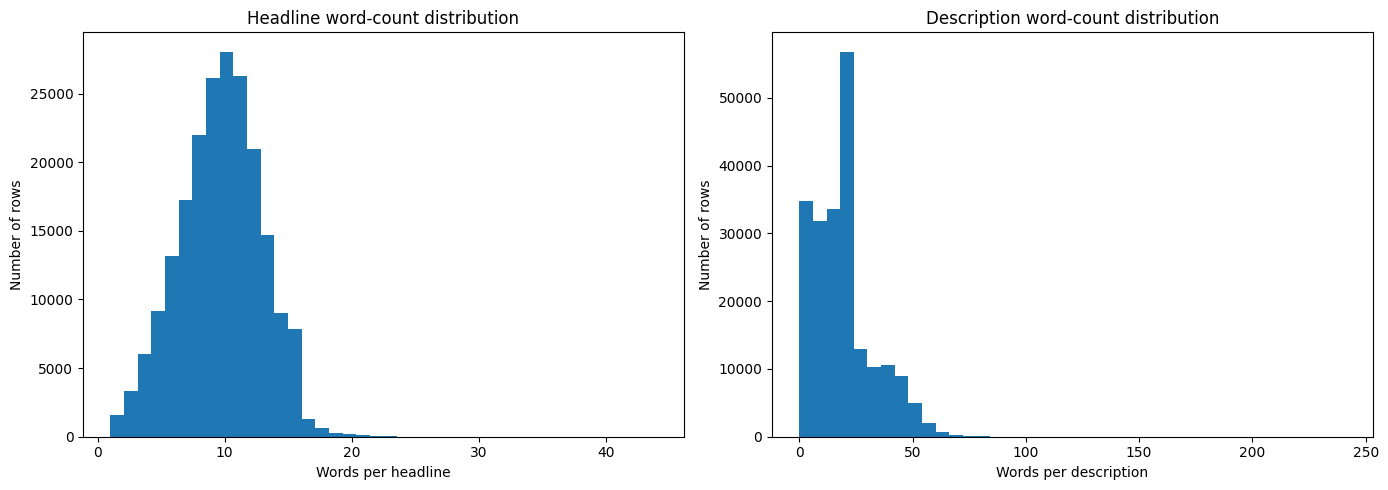

In [83]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["headline_word_count"], bins=40)
axes[0].set_title("Headline word-count distribution")
axes[0].set_xlabel("Words per headline")
axes[0].set_ylabel("Number of rows")

axes[1].hist(df["description_word_count"], bins=40)
axes[1].set_title("Description word-count distribution")
axes[1].set_xlabel("Words per description")
axes[1].set_ylabel("Number of rows")

plt.tight_layout()
plt.show()

## 3. Compare text length across categories


In [84]:
category_text_stats = (
    df.groupby("category")
      .agg(
          article_count=("headline", "size"),
          median_headline_words=("headline_word_count", "median"),
          median_description_words=("description_word_count", "median")
      )
      .sort_values("article_count", ascending=False)
)

display(category_text_stats.round(2))

,article_count,median_headline_words,median_description_words
category,,,
POLITICS,35478,10.0,15.0
WELLNESS,17896,8.0,26.0
ENTERTAINMENT,17321,11.0,10.0
TRAVEL,9875,8.0,23.0
STYLE & BEAUTY,9330,11.0,21.0
PARENTING,8740,9.0,25.0
HEALTHY LIVING,6684,9.0,15.0
QUEER VOICES,6337,10.0,17.0
FOOD & DRINK,6335,8.0,17.0


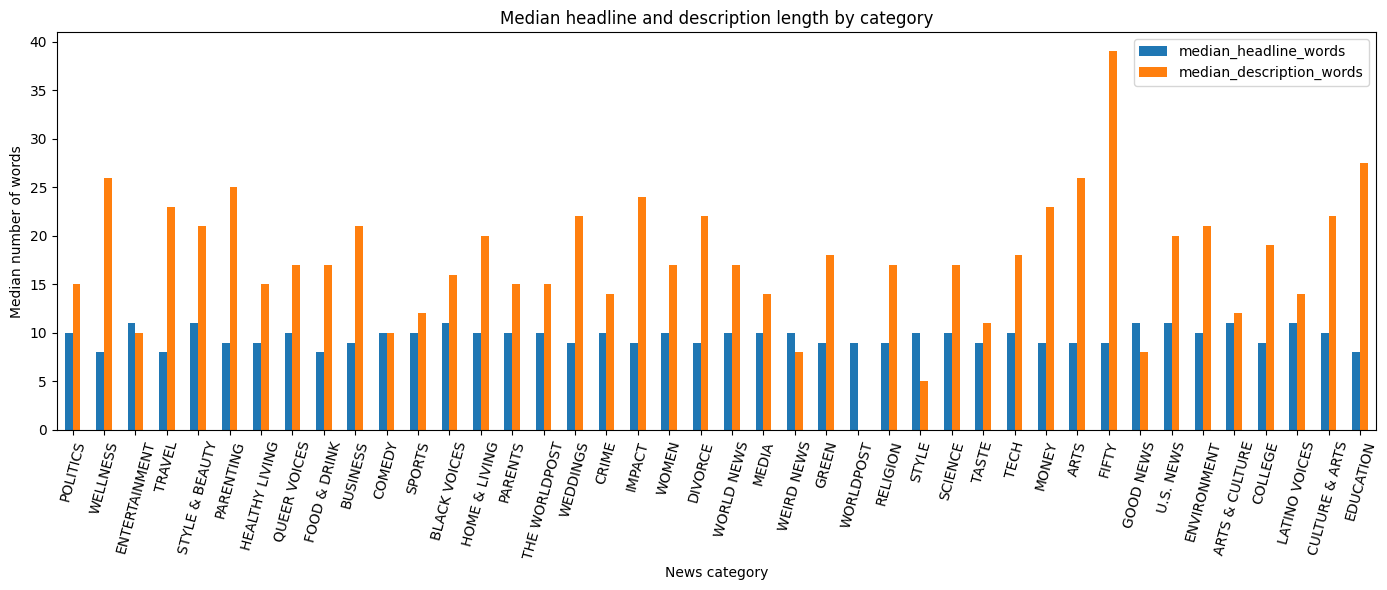

In [85]:
category_text_stats[["median_headline_words", "median_description_words"]].plot(
    kind="bar", figsize=(14, 6)
)
plt.title("Median headline and description length by category")
plt.xlabel("News category")
plt.ylabel("Median number of words")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 4. Inspect class imbalance

A classification dataset is imbalanced when some categories have many more examples than others. We report the counts and percentages used a stratified train/test split and evaluate with metrics such as macro-F1 as well as accuracy.

In [86]:
category_counts = df["category"].value_counts()
category_percentages = df["category"].value_counts(normalize=True).mul(100)

class_distribution = pd.DataFrame({
    "article_count": category_counts,
    "percentage": category_percentages
})

display(class_distribution.round(2))

print("Largest category:", category_counts.idxmax(),
      f"({category_counts.max():,} rows)")
print("Smallest category:", category_counts.idxmin(),
      f"({category_counts.min():,} rows)")
print("Largest/smallest category count ratio:",
      round(category_counts.max() / category_counts.min(), 2))

,article_count,percentage
category,,
POLITICS,35478,17.05
WELLNESS,17896,8.60
ENTERTAINMENT,17321,8.32
TRAVEL,9875,4.75
STYLE & BEAUTY,9330,4.48
PARENTING,8740,4.20
HEALTHY LIVING,6684,3.21
QUEER VOICES,6337,3.05
FOOD & DRINK,6335,3.04


Largest category: POLITICS (35,478 rows)
Smallest category: EDUCATION (1,014 rows)
Largest/smallest category count ratio: 34.99


## 5. URL cleaning confirmation


In [87]:
url_pattern = r"https?://\S+|(?<!\w)www\.\S+"

headline_url_mask = df["lower_headlines"].fillna("").str.contains(
    url_pattern, regex=True, na=False
)
description_url_mask = df["lower_description"].fillna("").str.contains(
    url_pattern, regex=True, na=False
)

print("Headline rows with URL-like text:", int(headline_url_mask.sum()))
print("Description rows with URL-like text:", int(description_url_mask.sum()))

display(df.loc[headline_url_mask, [
    "headline", "headline_clean", "category"
]].head(15))

display(df.loc[description_url_mask, [
    "short_description", "description_clean", "category"
]].head(15))

Headline rows with URL-like text: 2
Description rows with URL-like text: 152


,headline,headline_clean,category
94420,Wendy Williams Announces 12-City ‘Sit Down Tour’ Read more at http://www.eurweb.com/2015/07/wendy-williWendy Williams Announces 12-City ‘Sit Down Tour’ Read more at http://www.eurweb.com/2015/07/wggendy-williams-announces-12-city-sit-down-tour/#CzdwTvg7bx2ZhiMt.99ams-announces-12-city-sit-down-tour/#CzdwTvg7bx2ZhiMt.99,wendy williams announces 12-city ‘sit down tour’ read more at williams announces 12-city ‘sit down tour’ read more at,BLACK VOICES
174199,Georgia Students Struggle On Test Tied To Common Core Math Course | Www.ajc.com,georgia students struggle on test tied to common core math course |,PARENTING


,short_description,description_clean,category
25330,1. Call your representatives. You can find who you’re representatives are at https://whoismyrepresentative.com/ If you want,1. call your representatives. you can find who you’re representatives are at if you want,POLITICS
31791,"5. Pack Less. My favorite travel writer, Rick Steves, https://www.ricksteves.com says there are travelers who pack light","5. pack less. my favorite travel writer, rick steves, says there are travelers who pack light",TRAVEL
43536,http://data.huffingtonpost.com/2017/medicaid-expansion,,POLITICS
56555,"Researchers from the Rollins School of Public Health at Emory University unveiled a new website, www.preplocator.org, that","researchers from the rollins school of public health at emory university unveiled a new website, that",QUEER VOICES
56812,http://elections.huffingtonpost.com/2016/forecast/senate,,POLITICS
106569,"Scott Blankenship, founder and CEO of www.amplifydpledges.com, a social activism startup based in Berkeley, California, is concerned about the health risks and antibiotic-laden milk.","scott blankenship, founder and ceo of a social activism startup based in berkeley, california, is concerned about the health risks and antibiotic-laden milk.",GREEN
107409,"When the Black and Missing Foundation, Inc (www.BAMFI.org) began in 2008, 30 percent of all persons missing were of color. Sadly, that number has grown -- seemingly to a new record setting incline.","when the black and missing foundation, inc ( began in 2008, 30 percent of all persons missing were of color. sadly, that number has grown -- seemingly to a new record setting incline.",BLACK VOICES
133899,LUNCH Phone: 813-248-4961 Online: www.saturdaymorningmarket.com There are other dim sum choices in Tampa - China Yuan and,lunch phone: 813-248-4961 online: there are other dim sum choices in tampa - china yuan and,TRAVEL
134357,Mentally ill people aren’t killers. Angry people are. Read more on www.slate.com,mentally ill people aren’t killers. angry people are. read more on,WELLNESS
135262,"LIKE MotherWoman on Facebook: https://www.facebook.com/MotherWoman When my daughter was one and a half, I had to be away","like motherwoman on facebook: when my daughter was one and a half, i had to be away",PARENTING


## 6. Check whether cleaning left awkward whitespace or empty text


In [88]:
# Collapse repeated whitespace and trim the ends
df["headline_clean"] = df["headline_clean"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()
df["description_clean"] = df["description_clean"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()

print("Empty cleaned headlines:", int(df["headline_clean"].eq("").sum()))
print("Empty cleaned descriptions:", int(df["description_clean"].eq("").sum()))

display(df[[
    "headline", "headline_clean",
    "short_description", "description_clean"
]].sample(min(10, len(df)), random_state=42))

Empty cleaned headlines: 0
Empty cleaned descriptions: 19605


,headline,headline_clean,short_description,description_clean
102449,Wrongfully Convicted Man Reflects On 30 Years Behind Bars,wrongfully convicted man reflects on 30 years behind bars,,
44471,Global Artists Come Together For Anti-Trump Track Celebrating Queer Love,global artists come together for anti-trump track celebrating queer love,"""You will not ignore us.""","""you will not ignore us."""
127048,"For Your Viewing Pleasure, We Present Some Nude Piles As Art (NSFW)","for your viewing pleasure, we present some nude piles as art (nsfw)",,
160916,"Vintage IKEA Ad Says Store Is The ""Only Sensible Way To Buy Furniture"" (PHOTO)","vintage ikea ad says store is the ""only sensible way to buy furniture"" (photo)",We respectfully disagree.,we respectfully disagree.
126008,WATCH: Robotic 'Pack Mule' Can Take On Any Terrain,watch: robotic 'pack mule' can take on any terrain,,
96778,Jeb Bush Among Conservatives Criticizing Pope For Climate Change,jeb bush among conservatives criticizing pope for climate change,,
109166,Baptist Minister In Hot Water Over Comments On Ten Commandments,baptist minister in hot water over comments on ten commandments,,
193811,Black Voices Atlanta Spotlight: 'Facts of Life' Actress Kim Fields Loves The Professional Opportunities in Atlanta,black voices atlanta spotlight: 'facts of life' actress kim fields loves the professional opportunities in atlanta,"As the former capitol of the ""Old South,"" Atlanta is also the same city that gave birth to the Civil Rights Movement. Today","as the former capitol of the ""old south,"" atlanta is also the same city that gave birth to the civil rights movement. today"
54241,Amazon Set To Launch Convenience Stores: Report,amazon set to launch convenience stores: report,The expansion comes less than a year after the online retailer opened a chain of brick-and-mortar bookstores.,the expansion comes less than a year after the online retailer opened a chain of brick-and-mortar bookstores.
123796,'TMNT' Sequel Is Already In The Works,'tmnt' sequel is already in the works,,


## 7. Final EDA report

In [89]:
print("FINAL EDA SNAPSHOT")
print("-" * 40)
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Number of categories: {df['category'].nunique()}")
print(f"Duplicate full rows: {df.duplicated().sum():,}")
print(f"Missing headlines: {df['headline'].isna().sum():,}")
print(f"Empty/whitespace headlines: {df['headline'].fillna('').astype(str).str.strip().eq('').sum():,}")
print(f"Missing descriptions: {df['short_description'].isna().sum():,}")
print(f"Empty/whitespace descriptions: {df['short_description'].fillna('').astype(str).str.strip().eq('').sum():,}")
print(f"Median headline words: {df['headline_word_count'].median():.1f}")
print(f"Median description words: {df['description_word_count'].median():.1f}")
print(f"Most frequent category: {df['category'].value_counts().idxmax()}")
print(f"Least frequent category: {df['category'].value_counts().idxmin()}")

FINAL EDA SNAPSHOT
----------------------------------------
Rows: 208,102
Columns: 15
Number of categories: 42
Duplicate full rows: 0
Missing headlines: 0
Empty/whitespace headlines: 0
Missing descriptions: 0
Empty/whitespace descriptions: 19,603
Median headline words: 10.0
Median description words: 19.0
Most frequent category: POLITICS
Least frequent category: EDUCATION
